# 07b Plot extreme temperature distributions

In [21]:
%load_ext autoreload
%autoreload 2
    
import os
import sys
import xarray as xr
import pandas as pd
import netCDF4 as nc
import numpy as np
from dask.distributed import Client
from matplotlib.colors import ListedColormap
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.filterwarnings('ignore')

sys.path.append('/home/563/sc1326/repos/cdrmip_extremes')
from cdrmip_extremes.configs import data_dir, models, expts, colour_dict
from cdrmip_extremes import load_data, ext_freq, regions, utils, stats
from cdrmip_extremes.plotting import plot_regressions

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


In [2]:
client = Client(memory_limit=None,threads_per_worker=1,n_workers=28)

## Load Data

In [3]:
ext_freq_data = load_data.load_ext_freq_data()

In [34]:
ext_month_tas = load_data.load_ext_month_tas(period='anom',final=False)

In [5]:
thresholds = load_data.load_threshold_data()

In [6]:
areacella, mask_land, mask_ocean = load_data.load_fx()
mask_land, mask_ocean = mask_land.topo, mask_ocean.topo

In [7]:
gsat = load_data.load_gsat()

## Calculate rolling GSAT and peaks

In [35]:
gsat_rolling = {
    model: utils.rolling(
        ds.groupby('time.year').mean(dim='time'),
        21
    ) for model, ds in gsat.items()
}

ext_month_tas_rolling = {
    model: utils.rolling(
        ds,
        21
    ) for model, ds in ext_month_tas.items()
}

peaks = {
    model: dict(zip(['peak', 'peak_year'], utils.peak_warming(ds)))
    for model, ds in gsat_rolling.items()
}

## Perform regressions

In [36]:
def compute_patterns(data, gsat_rolling, peaks, start=None, end=None):
    patterns = {}

    for model, ds in data.items():
        ds = ds.tas

        peak_year = peaks[model]['peak_year']

        if start == 'peak':
            start = peak_year
        if end == 'peak':
            end = peak_year

        Y = ds.sel(year=slice(start, end))
        X = gsat_rolling[model].sel(year=slice(start, end))

        slope, r2 = stats.regress_pattern_with_r2(X, Y, time_dim='year')
        patterns[model] = {'slope':slope,'r2':r2}

    return patterns

In [37]:
pre_patterns = compute_patterns(
    ext_month_tas_rolling,
    gsat_rolling,
    peaks,
    end='peak'
)

post_patterns = compute_patterns(
    ext_month_tas_rolling,
    gsat_rolling,
    peaks,
    start='peak',
    end=280
)

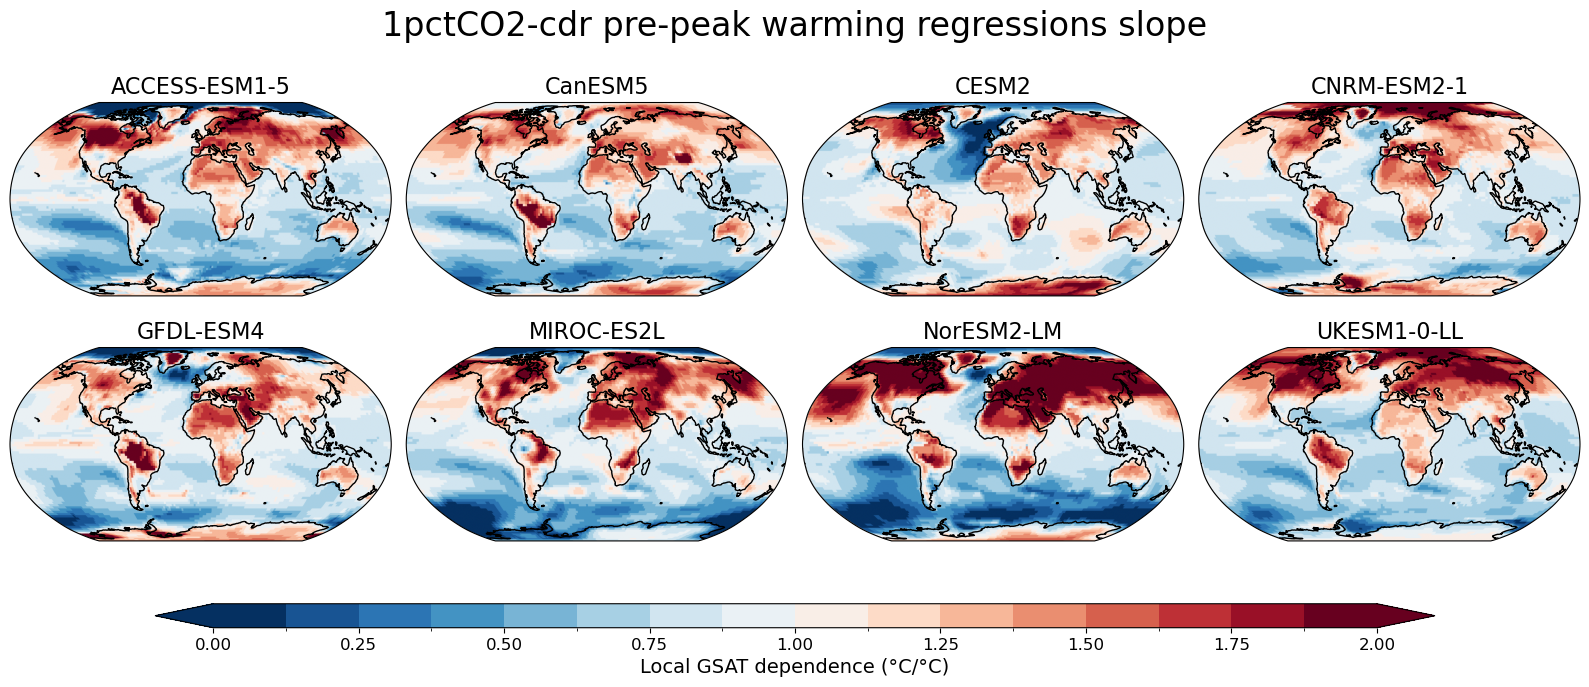

In [38]:
plot_regressions.plot_pattern(
    '1pctCO2-cdr',
    'pre-peak',
    pre_patterns,
    'slope',
    ext_type='heat'
)

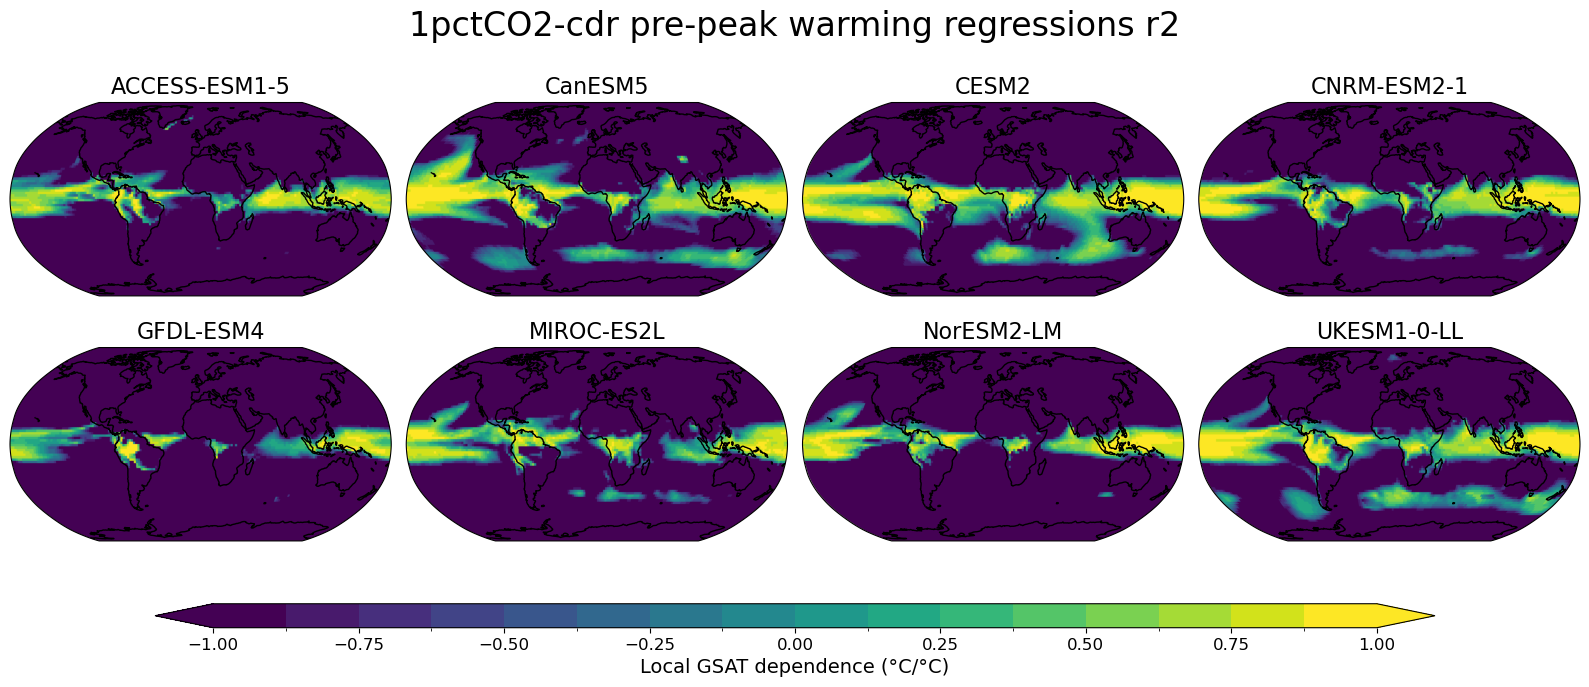

In [39]:
plot_regressions.plot_pattern(
    '1pctCO2-cdr',
    'pre-peak',
    pre_patterns,
    'r2',
    ext_type='heat'
)

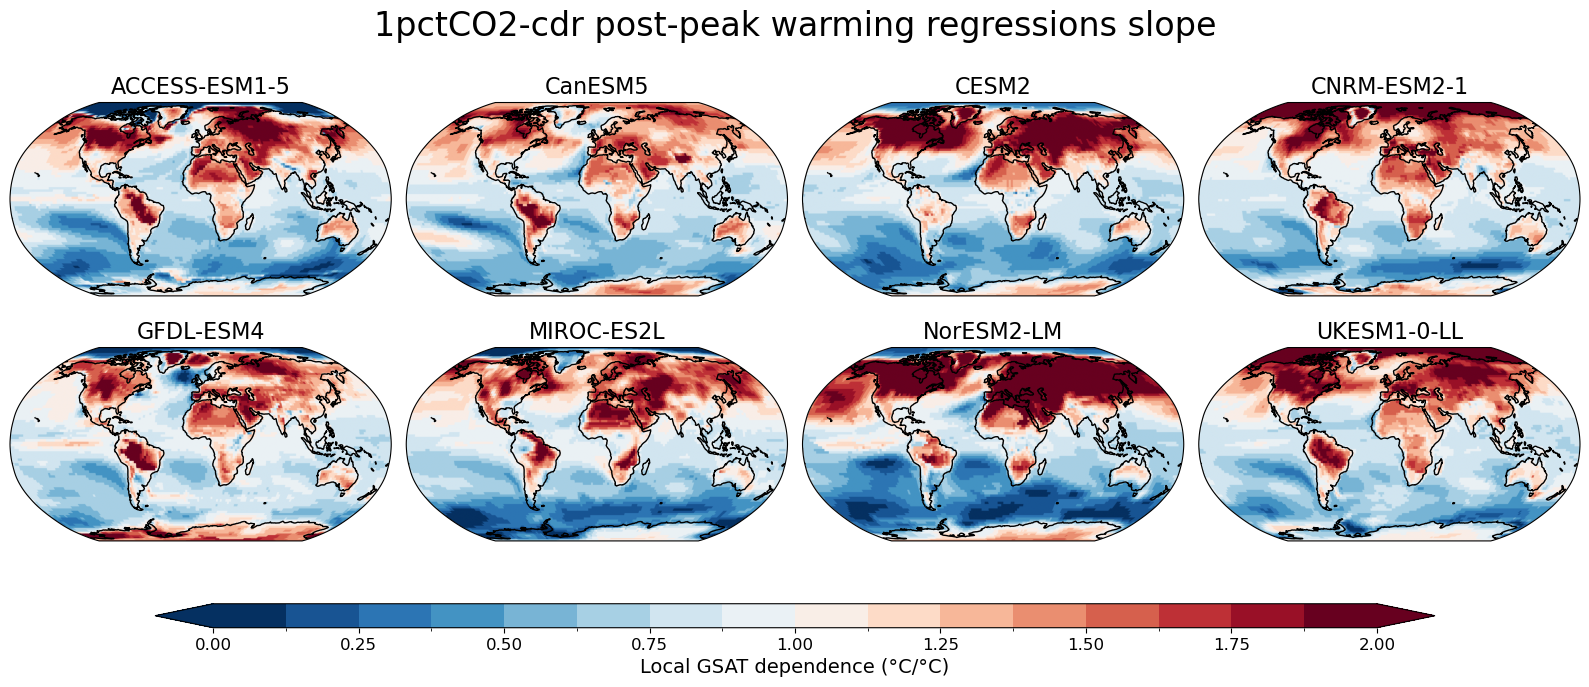

In [40]:
plot_regressions.plot_pattern(
    '1pctCO2-cdr',
    'post-peak',
    post_patterns,
    'slope',
    ext_type='heat'
)

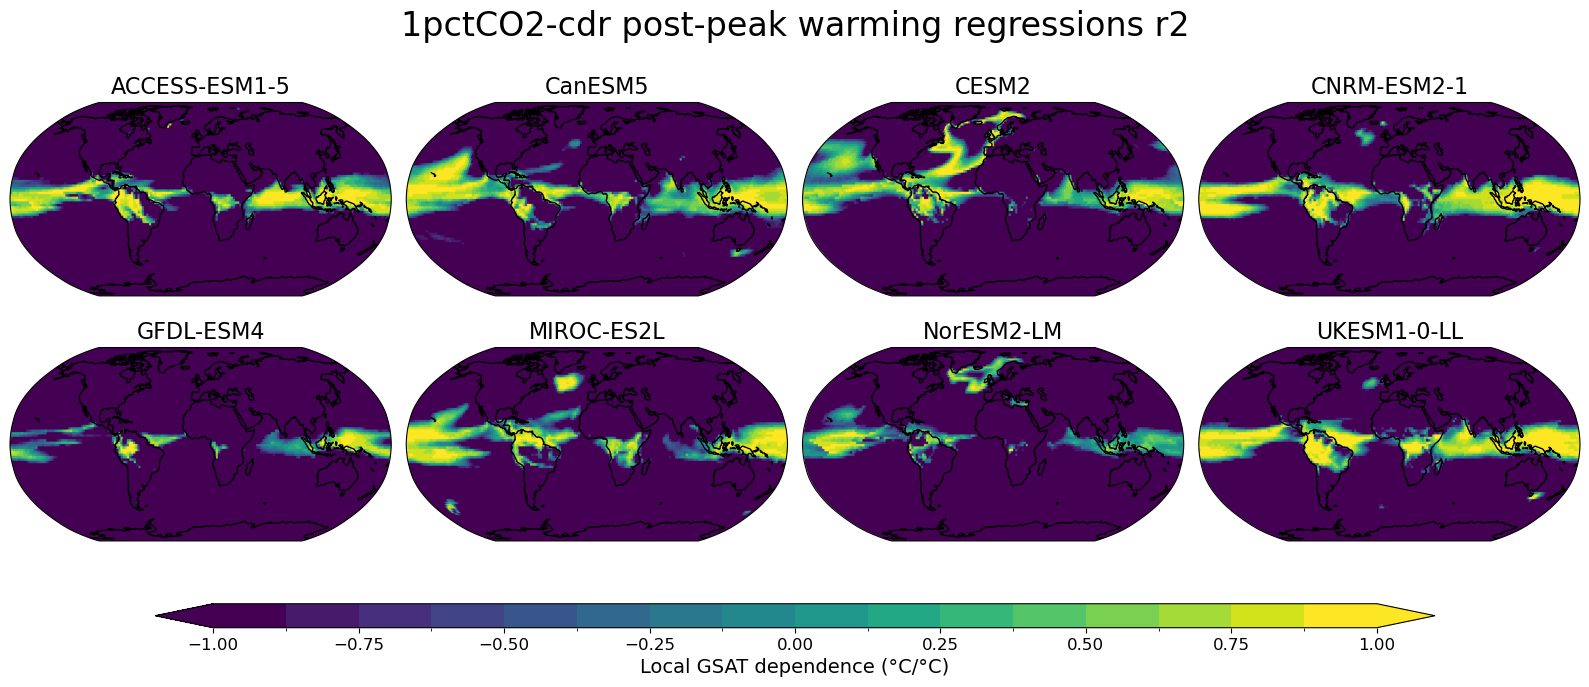

In [41]:
plot_regressions.plot_pattern(
    '1pctCO2-cdr',
    'post-peak',
    post_patterns,
    'r2',
    ext_type='heat'
)

# Calculate IPCC regions

In [42]:
region_dict = regions.region_dict
region_names = regions.region_names

In [45]:
regional_data = {}
for model, ds in ext_month_tas_rolling.items():
    all_regional, land_regional, ocean_regional = regions.regionmask_average(ds,mask_land,mask_ocean,'all')
    regional_data[model] = {'all':all_regional,'land':land_regional,'ocean':ocean_regional}

In [46]:
regional_data['ACCESS-ESM1-5']

{'all': <xarray.Dataset> Size: 737kB
 Dimensions:  (extrema: 2, year: 780, region: 58)
 Coordinates:
   * extrema  (extrema) <U4 32B 'heat' 'cold'
   * year     (year) int64 6kB 0 1 2 3 4 5 6 7 ... 773 774 775 776 777 778 779
   * region   (region) int64 464B 0 1 2 3 4 5 6 7 8 ... 50 51 52 53 54 55 56 57
     abbrevs  (region) <U4 928B 'GIC' 'NWN' 'NEN' 'WNA' ... 'EIO' 'SIO' 'SOO'
     names    (region) <U25 6kB 'Greenland/Iceland' ... 'Southern-Ocean'
 Data variables:
     tas      (extrema, year, region) float64 724kB 11.49 15.16 ... -2.03 -2.282,
 'land': <xarray.Dataset> Size: 737kB
 Dimensions:  (extrema: 2, year: 780, region: 58)
 Coordinates:
   * extrema  (extrema) <U4 32B 'heat' 'cold'
   * year     (year) int64 6kB 0 1 2 3 4 5 6 7 ... 773 774 775 776 777 778 779
   * region   (region) int64 464B 0 1 2 3 4 5 6 7 8 ... 50 51 52 53 54 55 56 57
     abbrevs  (region) <U4 928B 'GIC' 'NWN' 'NEN' 'WNA' ... 'EIO' 'SIO' 'SOO'
     names    (region) <U25 6kB 'Greenland/Iceland' ... 'So

## Plot IPCC Region Hysteresis Plots

In [74]:
def plot_regional_data(regional_data,regions,surface,ext_type,gsat_rolling,peaks,nrow,ncol,figsize):
    fig, axes = plt.subplots(nrow,ncol,figsize=figsize)

    for region, ax in zip(regions, axes.flat):
        for model in models:
            peak_year = peaks[model]['peak_year']
            da = regional_data[model][surface].sel(region=region_dict[region],extrema=ext_type).tas
            gsat = gsat_rolling[model]
            ax.plot(
                gsat.sel(year=slice(None,peak_year)),
                da.sel(year=slice(None,peak_year)),
                color=colour_dict[model],
                label=model
            )
            ax.plot(
                gsat.sel(year=slice(peak_year,339)),
                da.sel(year=slice(peak_year,339)),
                color=colour_dict[model],
                linestyle='--',
            )
        ax.set_title(region_names[region],fontsize=16)
        ax.set_xlabel('GSAT (°C)',fontsize=14)
        ax.set_ylabel('SAT Anomaly (°C)',fontsize=14)
        # ax.set_yticks([0,20,40,60])
        ax.tick_params(axis='both',labelsize=12)
        # ax.set_ylim([0,65])
        ax.grid()
    
    handles, labels = axes[0][0].get_legend_handles_labels()
    # Create a legend below all subplots
    fig.legend(
        handles,
        labels,
        loc='lower center',
        bbox_to_anchor=(0.5, -0.1),
        ncol=5,
        fontsize=16,
        frameon=False
    )
    if ext_type == 'heat':
        title = 'maximum'
    elif ext_type == 'cold':
        title = 'minimum'
    fig.suptitle(f'Month of {title} temperature vs GSAT',fontsize=24,y=1.01)
    fig.tight_layout()

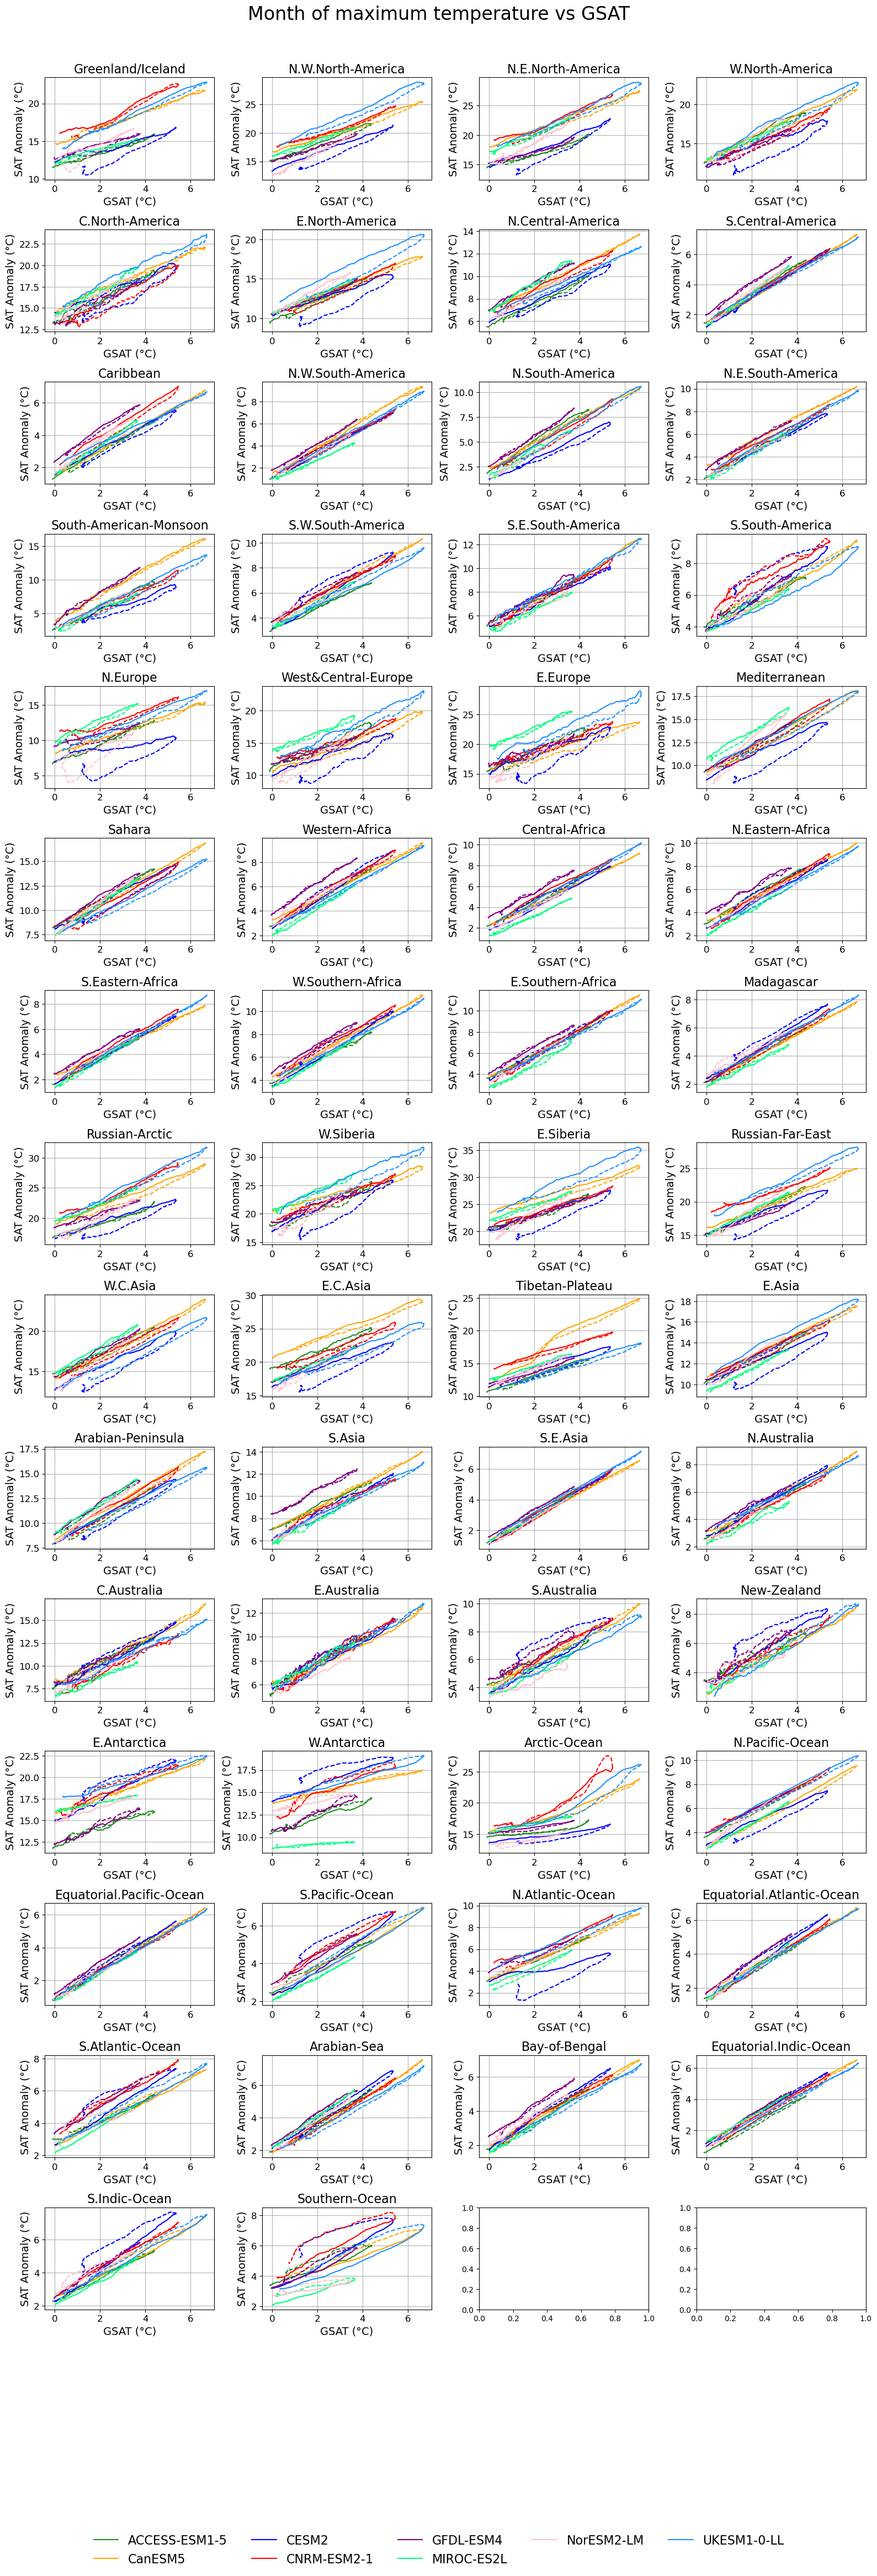

In [75]:
plot_regional_data(
    regional_data,
    list(region_dict.keys()),
    'all',
    'heat',
    gsat_rolling,
    peaks,
    nrow=15,
    ncol=4,
    figsize=(16,42)
)

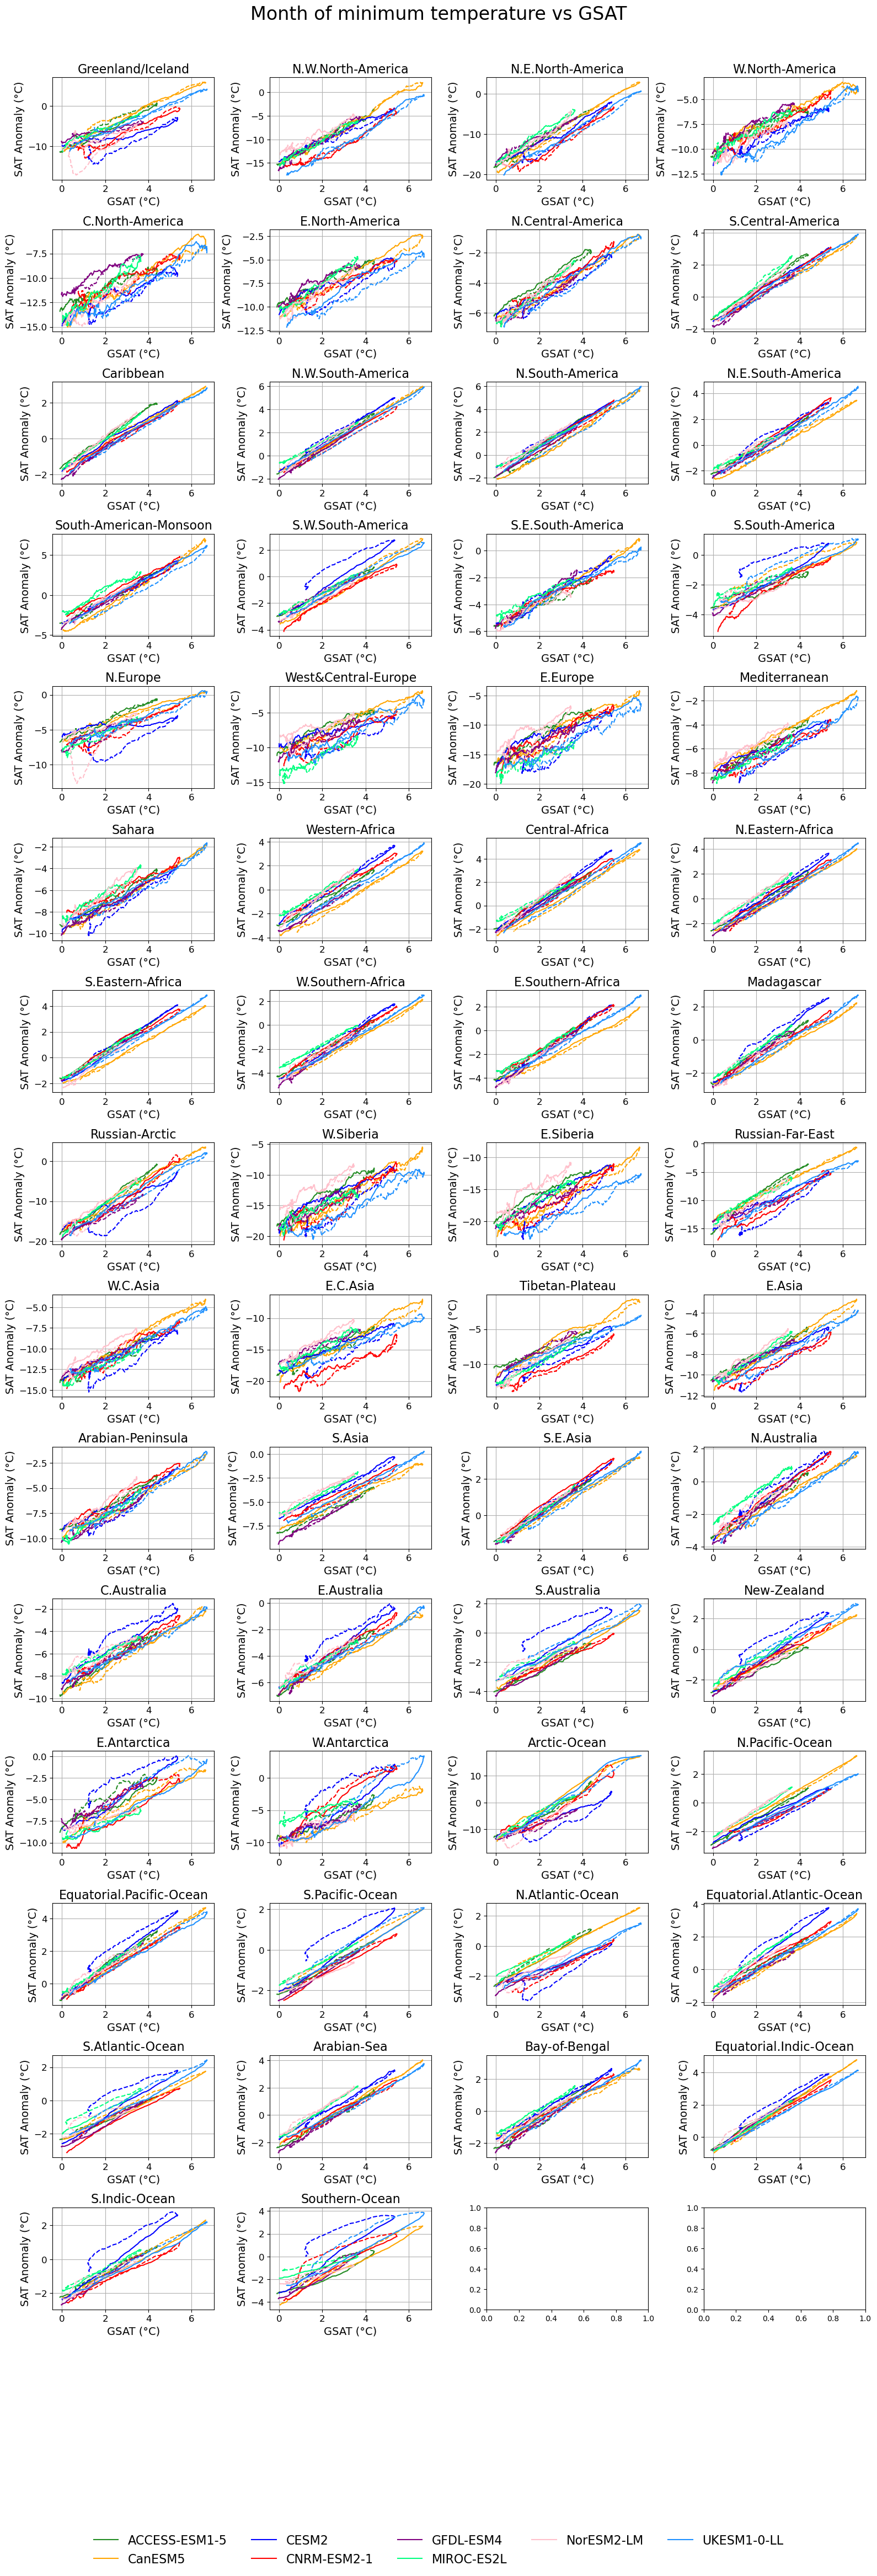

In [76]:
plot_regional_data(
    regional_data,
    list(region_dict.keys()),
    'all',
    'cold',
    gsat_rolling,
    peaks,
    nrow=15,
    ncol=4,
    figsize=(16,42)
)